# OR Intelligence · 01 · Data preparation (Member A)

Prepares the training data for the detector from **CholecInstanceSeg** and hands it to Member B through Google Drive.
**Get the data first** (`00_Download_CholecInstanceSeg` in Colab, or `scripts/download_synapse.py` locally), then run this notebook. It does not need a GPU.

| Step | What happens | WBS |
|---|---|---|
| 1 | Settings (the only cell you edit) | — |
| 2 | Connect Google Drive | — |
| 3 | Find (or re-unzip) the CholecInstanceSeg data from notebook 00 and check it | 2.1.1 |
| 4 | Convert instance polygons → YOLO boxes (6 instruments) + visual QA | 2.2.1 |
| 5 | Split **by surgery** into train / val / test | 2.2.2 |
| 6 | EDA: class balance, images per video, box sizes, co-occurrence | 2.4.1 |
| 7 | Save the ready dataset to Drive for Member B | hand-off |

**Where the data comes from:**
- **Locally (VS Code Jupyter, no GPU needed):** it reads the zips and the extracted image set from `~/Downloads`
  (where `scripts/download_synapse.py` put them) and writes everything to the gitignored `data/` folder
  (`data/processed/yolo/`, `data/local_out/` mirrors the Drive layout).
- Same Colab runtime as notebook 00 → it uses the already-unzipped folders in `/content/cholecinstanceseg` (no re-extraction).
- New runtime → it unzips the two zips that notebook 00 saved to `MyDrive/or-intelligence/data/cholecinstanceseg/`
  (needs `SAVE_IMAGE_ZIP_TO_DRIVE = True` in notebook 00, and ~50 GB free Colab disk).

Outputs in `MyDrive/or-intelligence/`: `data/yolo_dataset.zip`, `data/splits.json`, `results/eda/*`.
Copy `splits.json` to `data/splits/splits.json` in the repo, and the EDA figures to `docs/data/figures/`.

> Never commit the dataset, frames or videos to GitHub; they live in Drive (see `docs/data/LICENSES_AND_ETHICS.md`).
> CholecInstanceSeg is CC BY-NC-SA 4.0.

## 1 · Settings — the only cell you need to edit

In [1]:
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    DRIVE_DIR = "/content/drive/MyDrive/or-intelligence"            # shared team folder
    # Where notebook 00 unzipped CholecInstanceSeg (same runtime -> reused as-is)
    CIS_LOCAL = "/content/cholecinstanceseg"
    # Fallback for a fresh runtime: the zips notebook 00 copied to Drive
    CIS_DRIVE = f"{DRIVE_DIR}/data/cholecinstanceseg"
    IMAGES_DIR = None        # None -> unzip IMAGE_ZIP into CIS_LOCAL/images_raw
    WORK_DIR  = "/content/work"
else:                        # local Jupyter (e.g. VS Code): outputs go to the gitignored data/ folder
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DRIVE_DIR = str(REPO / "data" / "local_out")                    # mirror of the Drive folder layout
    CIS_LOCAL = str(REPO / "data" / "raw" / "cholecinstanceseg")
    CIS_DRIVE = str(Path.home() / "Downloads")                     # where scripts/download_synapse.py saved the zips
    # already-extracted image set (<split>/<video>/img_dir/*.png): reused instead of unzipping 22 GB again
    IMAGES_DIR = str(Path.home() / "Downloads" / "cholecinstance_seg_reference_image_set")
    WORK_DIR  = str(REPO / "data" / "processed")
IMAGE_ZIP = f"{CIS_DRIVE}/cholecinstance_seg_reference_image_set.zip"
ANN_ZIP   = f"{CIS_DRIVE}/cholecinstanceseg.zip"

SEED          = 42
TEST_FRACTION = 0.15   # CholecInstanceSeg's own test split is withheld, so we hold out this share of surgeries as test
JPEG_QUALITY  = 95     # frames are saved as .jpg (contract C2); PNG frames are re-encoded at this quality

# the 6 instruments: must match contracts/classes.json in the repo
CLASSES = ["grasper", "bipolar", "hook", "scissors", "clipper", "irrigator"]
DROP    = {"snare", "specimenbag", "specimen_bag"}   # CholecInstanceSeg's 7th class (snare) is not one of ours
ALIASES = {}   # e.g. {"bipolar_forceps": "bipolar"} if step 4 reports unknown label spellings

## 2 · Connect Google Drive (skipped when running locally)

In [2]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

import os, json, random, re, shutil, zipfile, glob, hashlib, datetime
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from PIL import Image

for sub in ["data", "runs", "weights", "results"]:
    os.makedirs(f"{DRIVE_DIR}/{sub}", exist_ok=True)
WORK = Path(WORK_DIR)             # fast local disk; Drive keeps the results
WORK.mkdir(parents=True, exist_ok=True)
print("output folder ready:", DRIVE_DIR)

output folder ready: C:\Users\fahad\Projects\or-intelligence\data\local_out


## 3 · Find the CholecInstanceSeg data and check it (WBS 2.1.1)

Annotations are read from `annotations_raw/<split>/<video>/ann_dir/*.json` and matched to the frames in
`images_raw/<split>/<video>/img_dir/`. Compare the printed counts with the paper (train 55 sequences / 26,830 frames,
val 18 / 4,284, test 22 / 10,819) and note them in `docs/data/LICENSES_AND_ETHICS.md`.

In [3]:
def unzip(zip_path, dest):
    if (Path(dest) / ".done").exists():
        print("already unzipped:", dest); return
    if not os.path.exists(zip_path):   # name differs? take any matching zip in the Drive folder
        hits = sorted(glob.glob(f"{CIS_DRIVE}/*{Path(zip_path).stem.split('_')[0]}*.zip"))
        assert hits, f"{zip_path} not found: run 00_Download_CholecInstanceSeg (same runtime, or with the Drive copy turned on)"
        zip_path = hits[0]
    print(f"unzipping {Path(zip_path).name} ({os.path.getsize(zip_path)/1e9:.1f} GB, "
          f"{shutil.disk_usage(Path(dest).anchor).free/1e9:.0f} GB free on disk) ...")
    os.makedirs(dest, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)
    (Path(dest) / ".done").touch()

def find_split_root(base):
    # Folder that directly contains train/ and val/
    for p in [Path(base), *sorted(Path(base).rglob("*"))]:
        if p.is_dir() and {"train", "val"} <= {c.name for c in p.iterdir() if c.is_dir()}:
            return p
    raise FileNotFoundError(f"no train/val folders under {base}")

unzip(ANN_ZIP, f"{CIS_LOCAL}/annotations_raw")
if IMAGES_DIR and Path(IMAGES_DIR).exists():
    img_root = find_split_root(IMAGES_DIR)
else:
    unzip(IMAGE_ZIP, f"{CIS_LOCAL}/images_raw")
    img_root = find_split_root(f"{CIS_LOCAL}/images_raw")
ann_root = find_split_root(f"{CIS_LOCAL}/annotations_raw")
print("images:     ", img_root, "\nannotations:", ann_root)

IMG_EXT = {".png", ".jpg", ".jpeg"}
image_index = {}   # (split, video) -> {file stem: image path}
for vdir in sorted(p for p in img_root.glob("*/*") if p.is_dir()):
    image_index[(vdir.parent.name, vdir.name)] = {
        p.stem: p for p in vdir.rglob("*") if p.suffix.lower() in IMG_EXT}

rec = {}           # output stem -> {json, image, split, video}
check = Counter(); unmatched = []
for j in sorted(ann_root.glob("*/*/ann_dir/*.json")):
    split, video = j.parent.parent.parent.name, j.parent.parent.name
    imgs = image_index.get((split, video), {})
    frame = j.stem.split("_")[-1]                  # 't80_VID07_000030' -> '000030'
    img = imgs.get(j.stem) or imgs.get(frame)
    check[f"{split} annotations"] += 1
    if img is None:
        unmatched.append(f"{split}/{video}/{j.name}"); continue
    stem = j.stem if not j.stem.isdigit() else f"{video}_{j.stem}"   # contract: <video>_<frame>
    if stem in rec:
        check["duplicate_stem"] += 1; continue
    rec[stem] = {"json": j, "image": img, "split": split, "video": video}
    check[f"{split} matched"] += 1
for split in sorted({k[0] for k in image_index}):
    check[f"{split} videos"] = sum(1 for k in image_index if k[0] == split)
    check[f"{split} images"] = sum(len(v) for k, v in image_index.items() if k[0] == split)
for k in sorted(check): print(f"{k:22s} {check[k]:>7,}")
print("annotations without a frame:", len(unmatched), unmatched[:5])
assert rec, "no annotation could be matched to a frame: look at the folder names printed above"
images_by_stem = {s: r["image"] for s, r in rec.items()}
print("example stems:", list(rec)[:3])
if os.path.exists(ANN_ZIP):
    print("sha256 of the annotation zip:", hashlib.sha256(open(ANN_ZIP, "rb").read()).hexdigest())

unzipping cholecinstanceseg.zip (0.1 GB, 517 GB free on disk) ...


images:      C:\Users\fahad\Downloads\cholecinstance_seg_reference_image_set 
annotations: C:\Users\fahad\Projects\or-intelligence\data\raw\cholecinstanceseg\annotations_raw\cholecinstanceseg


test annotations        10,819
test images             10,819
test matched            10,819
test videos                 22
train annotations       26,830
train images            26,830
train matched           26,830
train videos                55
val annotations          4,284
val images               4,284
val matched              4,284
val videos                  18
annotations without a frame: 0 []
example stems: ['t80_VID07_000000', 't80_VID07_000030', 't80_VID07_000060']
sha256 of the annotation zip: da179fcbc82c057ac61c852c67fdff2e9cb2413d524b501b094f7a36ec1de2f0


## 4 · Convert instance polygons → YOLO boxes (WBS 2.2.1)

CholecInstanceSeg uses LabelMe JSON: each `shape` is a polygon with a `label` and an instance `group_id`.
Polygons of the same instance (a tool split in two by occlusion) are merged, and each instance becomes one
`class cx cy w h` box (0–1), clipped to the image. Snare is dropped; frames without tools keep an empty label file.
**Read the printed label list**: anything shown as `unknown:` needs an entry in `ALIASES` (step 1).

In [4]:
NAME_TO_ID = {n: i for i, n in enumerate(CLASSES)}
stats, raw_labels = Counter(), Counter()

def image_size(d, img_path):
    for wk, hk in (("imageWidth", "imageHeight"), ("image_Width", "image_Height"), ("width", "height")):
        if d.get(wk) and d.get(hk):
            return float(d[wk]), float(d[hk])
    with Image.open(img_path) as im:
        return tuple(map(float, im.size))

def convert(r):
    d = json.load(open(r["json"], encoding="utf-8"))
    W, H = image_size(d, r["image"])
    instances = defaultdict(list)                 # (class name, instance id) -> all polygon points
    for i, sh in enumerate(d.get("shapes", [])):
        name = str(sh.get("label", "")).strip().lower()
        raw_labels[name] += 1
        name = ALIASES.get(name, name)
        if name in DROP:
            stats[f"dropped:{name}"] += 1; continue
        if name not in NAME_TO_ID:
            stats[f"unknown:{name}"] += 1; continue
        pts = sh.get("points") or []
        if len(pts) < 2:
            stats["shape_without_points"] += 1; continue
        gid = sh.get("group_id")
        instances[(name, gid if gid is not None else f"shape{i}")] += pts
    lines = []
    for (name, _), pts in instances.items():
        xs, ys = [float(p[0]) for p in pts], [float(p[1]) for p in pts]
        x1, x2 = max(0, min(xs)), min(W, max(xs))
        y1, y2 = max(0, min(ys)), min(H, max(ys))
        if x2 <= x1 or y2 <= y1:
            stats["degenerate_box"] += 1; continue
        cx, cy, w, h = (x1 + x2) / 2 / W, (y1 + y2) / 2 / H, (x2 - x1) / W, (y2 - y1) / H
        lines.append(f"{NAME_TO_ID[name]} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
        stats[name] += 1
    return lines

labels = {}                       # image stem -> YOLO label lines
for stem, r in rec.items():
    try:
        labels[stem] = convert(r)
    except Exception as e:
        stats["malformed_json"] += 1
        if stats["malformed_json"] <= 3: print("could not read", r["json"], e)
stats["empty_images"] = sum(1 for v in labels.values() if not v)
print("labels found in the JSON files:", dict(raw_labels.most_common()))
print(f"converted {len(labels)} images")
print(dict(stats))

# sanity checks from the WBS acceptance criteria
for s, lines in labels.items():
    for line in lines:
        c, *xywh = line.split()
        assert 0 <= int(c) <= 5 and all(0 <= float(v) <= 1 for v in xywh), (s, line)
print("all class ids in 0..5 and all coordinates in [0, 1]")

labels found in the JSON files: {'grasper': 40172, 'hook': 19429, 'bipolar': 2884, 'irrigator': 2443, 'clipper': 1399, 'scissors': 715, 'snare': 43}
converted 41933 images
{'grasper': 38416, 'hook': 19282, 'clipper': 1324, 'scissors': 712, 'bipolar': 2558, 'irrigator': 2420, 'dropped:snare': 43, 'empty_images': 4914}
all class ids in 0..5 and all coordinates in [0, 1]


In [5]:
# Visual QA: 50 random images with their boxes -> look at them and note problems in docs/data/qa_notes.md
from PIL import ImageDraw
import matplotlib.pyplot as plt
COLORS = ["#2563eb", "#7c3aed", "#dc2626", "#16a34a", "#ea580c", "#0891b2"]

def draw(stem):
    im = Image.open(images_by_stem[stem]).convert("RGB"); d = ImageDraw.Draw(im); W, H = im.size
    for line in labels[stem]:
        c, cx, cy, w, h = line.split(); c = int(c); cx, cy, w, h = map(float, (cx, cy, w, h))
        d.rectangle([(cx - w/2) * W, (cy - h/2) * H, (cx + w/2) * W, (cy + h/2) * H], outline=COLORS[c], width=3)
        d.text(((cx - w/2) * W + 3, (cy - h/2) * H + 3), CLASSES[c], fill=COLORS[c])
    return im

qa = random.Random(SEED).sample(sorted(labels), min(50, len(labels)))
os.makedirs(f"{DRIVE_DIR}/results/qa", exist_ok=True)
for s in qa:
    draw(s).save(f"{DRIVE_DIR}/results/qa/{s}.jpg")
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, s in zip(axes.flat, qa):
    ax.imshow(draw(s)); ax.set_title(s, fontsize=8); ax.axis("off")
plt.show()
print(f"{len(qa)} QA images saved to {DRIVE_DIR}/results/qa/")

50 QA images saved to C:\Users\fahad\Projects\or-intelligence\data\local_out/results/qa/


## 5 · Split by surgery (WBS 2.2.2)

CholecInstanceSeg reuses Cholec80 video numbers across its parts (e.g. a CholecT50 and a Cholec80 folder can be the same
surgery), so frames are grouped **by video number** (`VID07`), and one surgery never ends up in two splits.

- **val** = the dataset's recommended val videos (any surgery that is also in its train folder moves to val, to avoid leakage)
- **test** = the dataset's recommended test videos (in the Synapse release), or, if a copy has no test folder, `TEST_FRACTION` of the train surgeries (seeded, every class present)
- **train** = the rest

**Check that the printed groups look right** (adjust `surgery()` if the folder names use another pattern).

In [6]:
def video_id(stem):
    # contract C2: recovers the video from a stem like 't80_VID07_000030' -> 't80_VID07'
    m = re.match(r"(.+)_\d+$", stem)
    return m.group(1) if m else stem.split("_")[0]

def surgery(stem):
    # 'VID07', 'VID-07', 't80_VID07' ... -> 'VID07'
    m = re.search(r"VID[-_]?(\d+)", f"{rec[stem]['video']} {stem}", re.I)
    return f"VID{int(m.group(1)):02d}" if m else rec[stem]["video"]

videos = defaultdict(list)            # surgery -> image stems
official = defaultdict(set)           # surgery -> dataset split folders it appears in
for stem in labels:
    videos[surgery(stem)].append(stem); official[surgery(stem)].add(rec[stem]["split"])
print(f"{len(videos)} surgeries:", {v: len(s) for v, s in sorted(videos.items())})
shared = sorted(g for g, s in official.items() if len(s) > 1)
print("surgeries in more than one dataset split (kept in one only):", shared)

def class_counts(stems):
    c = Counter()
    for s in stems:
        for line in labels[s]:
            c[CLASSES[int(line.split()[0])]] += 1
    return c

def has_all(groups):
    c = class_counts([s for g in groups for s in videos[g]])
    return all(c[k] > 0 for k in CLASSES)

val  = sorted(g for g in videos if "val" in official[g])
test = sorted(g for g in videos if "test" in official[g] and g not in val)
pool = sorted(g for g in videos if g not in val and g not in test)
if not test:                                          # test is withheld: carve it from train surgeries
    n_test = max(1, round(len(videos) * TEST_FRACTION))
    rng, best = random.Random(SEED), None
    for attempt in range(500):
        rng.shuffle(pool)
        cand = {"train": sorted(pool[n_test:]), "val": val, "test": sorted(pool[:n_test])}
        if has_all(cand["train"]) and has_all(cand["test"]):
            best = cand; break
    if best is None:
        rng.shuffle(pool)
        best = {"train": sorted(pool[n_test:]), "val": val, "test": sorted(pool[:n_test])}
        print("WARNING: no seeded split has every class in train and test")
else:
    best = {"train": pool, "val": val, "test": test}
for k in best:
    missing = [c for c in CLASSES if class_counts([s for g in best[k] for s in videos[g]])[c] == 0]
    if missing: print(f"WARNING: {k} has no boxes of {missing}")

all_v = best["train"] + best["val"] + best["test"]
assert len(all_v) == len(set(all_v)), "a surgery is in more than one split!"
print("leakage check passed:", {k: len(v) for k, v in best.items()}, "surgeries per split,",
      {k: sum(len(videos[g]) for g in v) for k, v in best.items()}, "images")

DS = WORK / "yolo"
if DS.exists(): shutil.rmtree(DS)
for k in best:
    (DS / "images" / k).mkdir(parents=True); (DS / "labels" / k).mkdir(parents=True)

def export(job):
    stem, k = job
    src, dst = images_by_stem[stem], DS / "images" / k / f"{stem}.jpg"
    if src.suffix.lower() in (".jpg", ".jpeg"):
        shutil.copy(src, dst)
    else:
        with Image.open(src) as im:
            im.convert("RGB").save(dst, quality=JPEG_QUALITY)
    (DS / "labels" / k / f"{stem}.txt").write_text("\n".join(labels[stem]))

jobs = [(s, k) for k, groups in best.items() for g in groups for s in videos[g]]
with ThreadPoolExecutor(8) as ex:
    for i, _ in enumerate(ex.map(export, jobs), 1):
        if i % 5000 == 0: print(f"  {i:,}/{len(jobs):,} images written")
(DS / "dataset.yaml").write_text("path: .\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
                                 + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASSES)))
json.dump(best, open(f"{DRIVE_DIR}/data/splits.json", "w"), indent=2)
print(f"wrote {len(jobs):,} images to {DS}; saved splits.json to Drive")

85 surgeries: {'VID01': 3014, 'VID02': 124, 'VID03': 195, 'VID04': 70, 'VID05': 103, 'VID06': 93, 'VID07': 152, 'VID08': 64, 'VID09': 240, 'VID10': 59, 'VID103': 74, 'VID11': 108, 'VID110': 73, 'VID111': 72, 'VID12': 1731, 'VID13': 55, 'VID14': 1709, 'VID15': 2059, 'VID16': 99, 'VID17': 320, 'VID18': 2103, 'VID19': 81, 'VID20': 160, 'VID21': 59, 'VID22': 1533, 'VID23': 1636, 'VID24': 960, 'VID25': 2450, 'VID26': 2094, 'VID27': 2485, 'VID28': 560, 'VID29': 2351, 'VID30': 98, 'VID31': 132, 'VID32': 71, 'VID33': 59, 'VID34': 60, 'VID35': 2347, 'VID36': 80, 'VID37': 480, 'VID38': 103, 'VID39': 55, 'VID40': 75, 'VID41': 104, 'VID42': 124, 'VID43': 3083, 'VID44': 105, 'VID45': 113, 'VID46': 56, 'VID47': 76, 'VID48': 2075, 'VID49': 56, 'VID50': 63, 'VID51': 99, 'VID52': 2767, 'VID53': 110, 'VID54': 104, 'VID55': 240, 'VID56': 62, 'VID57': 88, 'VID58': 200, 'VID59': 59, 'VID60': 85, 'VID61': 147, 'VID62': 68, 'VID63': 115, 'VID64': 80, 'VID65': 63, 'VID66': 61, 'VID67': 79, 'VID68': 66, 'VID69

leakage check passed: {'train': 45, 'val': 18, 'test': 22} surgeries per split, {'train': 26830, 'val': 4284, 'test': 10819} images


  5,000/41,933 images written


  10,000/41,933 images written


  15,000/41,933 images written


  20,000/41,933 images written


  25,000/41,933 images written


  30,000/41,933 images written


  35,000/41,933 images written


  40,000/41,933 images written


wrote 41,933 images to C:\Users\fahad\Projects\or-intelligence\data\processed\yolo; saved splits.json to Drive


## 6 · EDA (WBS 2.4.1)

Four figures + a counts table, saved to `results/eda/`. Summarise them in `docs/data/EDA.md`, including recommendations for Member B (e.g. which class to oversample).

,train,val,test,total
grasper,25698,4017,8701,38416
bipolar,1762,270,526,2558
hook,12675,1759,4848,19282
scissors,450,113,149,712
clipper,899,99,326,1324
irrigator,1189,122,1109,2420


imbalance ratio (max/min class): 53.96
share of small boxes (< 1% of the image): 0.078


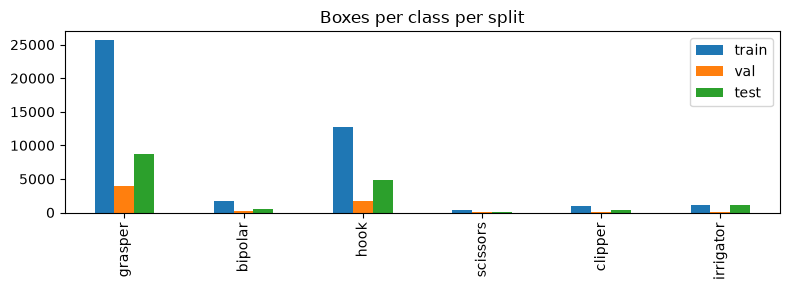

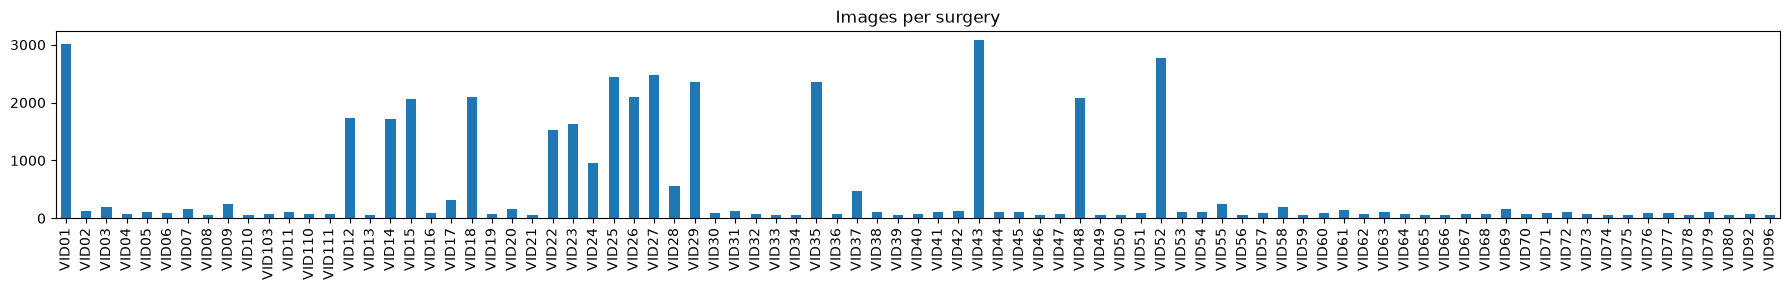

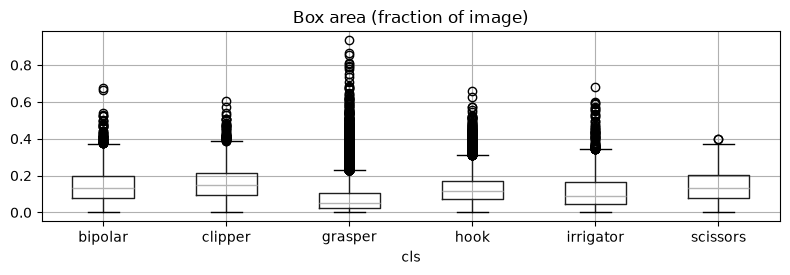

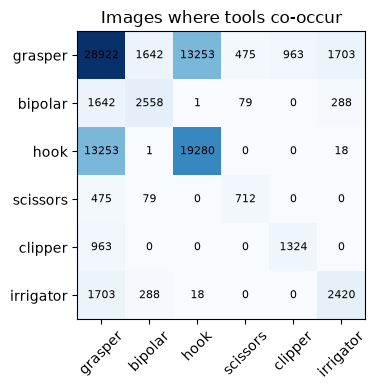

In [7]:
import pandas as pd
EDA = f"{DRIVE_DIR}/results/eda"; os.makedirs(EDA, exist_ok=True)
split_of = {s: k for k in best for g in best[k] for s in videos[g]}

counts = pd.DataFrame({k: class_counts([s for g in best[k] for s in videos[g]]) for k in best}).reindex(CLASSES).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
display(counts); counts.to_csv(f"{EDA}/boxes_per_class_per_split.csv")
print("imbalance ratio (max/min class):", round(counts["total"].max() / max(counts["total"].min(), 1), 2))

boxes = pd.DataFrame([{"split": split_of[s], "video": surgery(s), "cls": CLASSES[int(l.split()[0])],
                       "area": float(l.split()[3]) * float(l.split()[4])} for s in split_of for l in labels[s]])
print("share of small boxes (< 1% of the image):", round((boxes.area < 0.01).mean(), 3))

fig, ax = plt.subplots(figsize=(8, 3)); counts.drop(columns="total").plot.bar(ax=ax, title="Boxes per class per split")
plt.tight_layout(); plt.savefig(f"{EDA}/boxes_per_class_per_split.png"); plt.show()

fig, ax = plt.subplots(figsize=(18, 3)); pd.Series({v: len(s) for v, s in sorted(videos.items())}).plot.bar(ax=ax, title="Images per surgery")
plt.tight_layout(); plt.savefig(f"{EDA}/images_per_video.png"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3)); boxes.boxplot(column="area", by="cls", ax=ax); ax.set_title("Box area (fraction of image)")
plt.suptitle(""); plt.tight_layout(); plt.savefig(f"{EDA}/box_size_distribution.png"); plt.show()

co = pd.DataFrame(0, index=CLASSES, columns=CLASSES)
for s in split_of:
    present = sorted({CLASSES[int(l.split()[0])] for l in labels[s]})
    for i in present:
        for j in present:
            co.loc[i, j] += 1
fig, ax = plt.subplots(figsize=(5, 4)); im = ax.imshow(co.values, cmap="Blues")
ax.set_xticks(range(6), CLASSES, rotation=45); ax.set_yticks(range(6), CLASSES); ax.set_title("Images where tools co-occur")
for i in range(6):
    for j in range(6):
        ax.text(j, i, co.values[i, j], ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(f"{EDA}/class_cooccurrence.png"); plt.show()

## 7 · Save the ready dataset to Drive (hand-off to Member B)

In [8]:
# frames are already JPEG, so the zip only stores them (much faster than compressing); built locally, then copied
out_zip = f"{DRIVE_DIR}/data/yolo_dataset.zip"
local_zip = WORK / "yolo_dataset.zip" if IN_COLAB else Path(out_zip)
with zipfile.ZipFile(local_zip, "w", zipfile.ZIP_STORED) as z:
    for p in sorted(DS.rglob("*")):
        if p.is_file():
            z.write(p, p.relative_to(DS))
if IN_COLAB:
    shutil.copy(local_zip, out_zip)
print("saved", out_zip, f"({os.path.getsize(out_zip) / 1e9:.2f} GB)")
print("Tell Member B it is ready, and post this split summary in your PR:")
display(counts)

saved C:\Users\fahad\Projects\or-intelligence\data\local_out/data/yolo_dataset.zip (4.44 GB)
Tell Member B it is ready, and post this split summary in your PR:


,train,val,test,total
grasper,25698,4017,8701,38416
bipolar,1762,270,526,2558
hook,12675,1759,4848,19282
scissors,450,113,149,712
clipper,899,99,326,1324
irrigator,1189,122,1109,2420


## Done — hand-off

| File in Drive | Who needs it | Repo location |
|---|---|---|
| `data/yolo_dataset.zip` | Member B (02_Model notebook) | Drive only, never committed |
| `data/splits.json` | Report | `data/splits/splits.json` |
| `results/eda/*.png`, `*.csv` | Member B, report, slides | `docs/data/figures/` |
| `results/qa/*.jpg` | You (QA notes) | notes in `docs/data/qa_notes.md` |